# Continuous Optimisation

## Imports

In [2]:
import numpy as np
from numpy import linalg as LA
from typing import Tuple, Callable, Optional
import matplotlib.pyplot as plt

## Medical Inverse Problem

In [3]:
class MedicalModel:
    def __init__(self, A: np.ndarray, y: np.ndarray):
        self.A = np.asarray(A, dtype=float).copy()
        self.y = np.asarray(y, dtype=float).copy()

        self.m, self.n = self.A.shape
        assert self.y.shape == (self.m,)

    def _model(self, theta: np.ndarray) -> np.ndarray:
        return self.A @ np.exp(-theta)

    def _objective(self, theta: np.ndarray) -> float:
        """Compute the least-squares objective."""
        with np.errstate(over="ignore", invalid="ignore"):
            return float(LA.norm(self._model(theta) - self.y)**2)

    def _gradient(self, theta: np.ndarray) -> np.ndarray:
        """Compute the gradient of the objective."""
        D = np.diag(np.exp(-theta))
        return -2 * D @ self.A.T @ (self._model(theta) - self.y)

    def _hessian(self, theta: np.ndarray) -> np.ndarray:
        """Compute the Hessian of the objective."""
        D = np.diag(np.exp(-theta))
        AD = self.A @ D

        return 2 * (
            np.diag(D @ self.A.T @ (self._model(theta) - self.y))
            + AD.T @ AD
        )

    def gradient_descent(
        self,
        u_0: np.ndarray,
        alpha: float,
        epsilon: float = 1e-8,
        max_iter: int = 10000,
        track_history: bool = False): # for plotting 
        """ Gradient descent algorithm
        Args:
            u_0 (np.ndarray): initial point
            alpha (float): step size
            epsilon (float, optional): error tolerance. Defaults to 1e-8.
            max_iter (int, optional): maximum nr. of iterations. Defaults to 10000.

        Raises:
            ValueError: Objective function value became infinite
            RuntimeError: Way too many iterations for the algorithm
        """
        assert alpha > 0
        assert epsilon > 0 and max_iter > 0

        x_k = np.asarray(u_0, dtype=float).copy()
        history = {'obj': [], 'grad': [], 'theta': []}

        for k in range(max_iter + 1):
            grad_k = self._gradient(x_k)
            grad_norm = LA.norm(grad_k)
            obj_k = self._objective(x_k)

            if not np.isfinite(obj_k) or not np.isfinite(grad_norm):
                raise ValueError("Objective or gradient became non-finite")

            if track_history:
                history['obj'].append(float(obj_k))
                history['grad'].append(float(grad_norm))
                history['theta'].append(x_k.copy())

            if grad_norm < epsilon:
                result = (x_k, k, obj_k)
                return (*result, history) if track_history else result

            if k == max_iter:
                break

            x_k -= alpha * grad_k

        raise RuntimeError(f"Did not converge within {max_iter} iterations")


    def armijo_condition(self,
        u: np.ndarray,
        d: np.ndarray,
        alpha: float,
        c: float
        ) -> bool:
        """Check E(u + alpha * d) <= E(u) + c* alpha * grad E(u)^T * d.

        Args:
            d (np.ndarray): descent direction
            c (float): constant coefficient
            alpha (float): step size

        Returns:
            bool: Is the Armijo condition satisfied.
        """        
        assert (0 < c and c < 1), f"c = {c} is not in (0, 1)."
        assert 0 < alpha, f"alpha = {alpha} is not > 0."
        step = self._objective(u + alpha * d)
        current = self._objective(u)
        change = c * alpha * self._gradient(u).T @ d
        return bool(np.isfinite(step) and step <= current + change)  

    def backtracking(self,
        u_k: np.ndarray,
        d_k: np.ndarray,
        alpha_0: float = 1.0,
        rho: float = 0.5, 
        c: float = 1e-4,
        max_iter: int = 10000
        ) -> float:
        """backtracking line search for sufficiently optimal alpha

        Args:
            u_k (np.ndarray): current point
            d_k (np.ndarray): descent direcion
            alpha_0 (float, optional): initial alpha. Defaults to 1.0.
            rho (float, optional): constant rho. Defaults to 0.5.
            c (float, optional): constant c. Defaults to 1e-4.
            max_iter (int, optional): maximum iterations (for debugging). Defaults to 10000.

        Returns:
            float: new sufficient alpha
        """        
        assert (0 < c and c < 1), f"c = {c} is not in (0, 1)."
        assert 0 < alpha_0, f"alpha = {alpha_0} is not > 0."
        assert (0 < rho and rho < 1), f"rho = {rho} is not in (0, 1)."
        alpha_new = alpha_0
        for _ in range(max_iter):
            
            if self.armijo_condition(u_k, d_k, alpha_new, c):
                return float(alpha_new)
            
            alpha_new *= rho

        raise RuntimeError("Backtracking failed to find an Armijo step.")

    def GD_inexact_line_search(self,
        u_0: np.ndarray,
        alpha_0: float = 1.0,
        rho: float = 0.5,
        c: float = 1e-4,
        epsilon: float = 1e-8,
        max_iter: int = 10000
        ) -> Tuple[np.ndarray, int, float]:
        """Gradient Descent with Inexact Line Search

        Args:
            u_0 (np.ndarray): initial point
            alpha_0 (float, optional): initial alpha. Defaults to 1.0.
            rho (float, optional): constant rho. Defaults to 0.5.
            c (float, optional): constant c. Defaults to 1e-4.
            epsilon (float, optional): error margin. Defaults to 1e-8.
            max_iter (int, optional): maximum iterations (for debugging). Defaults to 10000.

        Raises:
            ValueError: Objective function value became infinite.
            RuntimeError: Way too many iterations for the algorithm.

        Returns:
            Tuple[np.ndarray, int, float]: Returns current position, current step number, and current objective value.
        """        
        assert 0 < epsilon, f"epsilon = {epsilon} is not > 0."
        assert (0 < c and c < 1), f"c = {c} is not in (0, 1)."
        assert 0 < alpha_0, f"alpha = {alpha_0} is not > 0."
        assert (0 < rho and rho < 1), f"rho = {rho} is not in (0, 1)."
        
        u_k = np.asarray(u_0, dtype=float).copy()
        alpha_k = alpha_0

        for k in range(max_iter):
            grad_k = self._gradient(u_k) # = d_k
            grad_norm = LA.norm(grad_k)
            
            if grad_norm < epsilon:
                return u_k, k, self._objective(u_k)

            alpha_k = self.backtracking(u_k=u_k,d_k=(-grad_k),alpha_0=alpha_0,rho=rho,c=c)
            u_k -= alpha_k * grad_k
            
            if not np.isfinite(self._objective(u_k)):
                raise ValueError("Objective became non-finite")
    
        raise RuntimeError(f"Did not converge within {max_iter} iterations")

    def heavy_ball(
        self,
        u_0: np.ndarray,
        alpha: float,
        beta: float,
        epsilon: float = 1e-8,
        max_iter: int = 10000,
        track_history: bool = False
        ) -> Tuple[np.ndarray, int, float]:
        """Heavy-ball method as presented by Algorithm 4.1 in the Lecture Notes.

        Args:
            u_0 (np.ndarray): Initial point u_0
            alpha (float): Step size
            beta (float): Momentum parameter
            epsilon (float, optional): Error margin. Defaults to 1e-8.
            max_iter (int, optional): Maximum number of iterations. Defaults to 10000.
            track_history (bool, optional): History tracking for data and plotting. Defaults to False.

        Raises:
            ValueError: Objective or gradeint becomes non-finite.
            RuntimeError: Maximum number of iterations reached.

        Returns:
            Tuple[np.ndarray, int, float]: Returns current position, current step number, and current objective value.
        """        
        assert alpha > 0
        assert 0 <= beta < 1
        assert epsilon > 0 and max_iter > 0

        x_k = np.asarray(u_0, dtype=float).copy()
        x_k_prev = x_k.copy()  # x_{-1} = x_0
        history = {'obj': [], 'grad': [], 'theta': []}

        for k in range(max_iter + 1):
            grad_k = self._gradient(x_k)
            grad_norm = LA.norm(grad_k)
            obj_k = self._objective(x_k)

            if not np.isfinite(obj_k) or not np.isfinite(grad_norm):
                raise ValueError("Objective or gradient became non-finite")

            if track_history:
                history['obj'].append(float(obj_k))
                history['grad'].append(float(grad_norm))
                history['theta'].append(x_k.copy())

            if grad_norm < epsilon:
                result = (x_k, k, obj_k)
                return (*result, history) if track_history else result

            if k == max_iter:
                break

            x_k_next = x_k - alpha * grad_k + beta * (x_k - x_k_prev)
            x_k_prev, x_k = x_k, x_k_next

        raise RuntimeError(f"Did not converge within {max_iter} iterations")

    def nesterov(
            self,
            u_0: np.ndarray,
            alpha: float,
            beta: float,
            epsilon: float = 1e-8,
            max_iter: int = 10000,
            track_history: bool = False
            ) -> Tuple[np.ndarray, int, float]:
            """Nesterov's accelerated gradient method as presented by Algorithm 4.2 in the Lecture Notes.
    
            Args:
                u_0 (np.ndarray): Initial point u_0
                alpha (float): Step size
                beta (float): Momentum parameter
                epsilon (float, optional): Error margin. Defaults to 1e-8.
                max_iter (int, optional): Maximum number of iterations. Defaults to 10000.
                track_history (bool, optional): History tracking for data and plotting. Defaults to False.
    
            Raises:
                ValueError: Objective or gradeint becomes non-finite.
                ValueError: Extrapolated gradient became non-finite.
                RuntimeError: Maximum number of iterations reached.
    
            Returns:
                Tuple[np.ndarray, int, float]: Returns current position, current step number, and current objective value.
            """
            assert alpha > 0
            assert 0 <= beta < 1
            assert epsilon > 0 and max_iter > 0
    
            x_k = np.asarray(u_0, dtype=float).copy()
            x_k_prev = x_k.copy()  # x{-1} = x_0
            history = {'obj': [], 'grad': [], 'theta': []}
    
            for k in range(max_iter + 1):
                grad_k = self._gradient(x_k)
                grad_norm = LA.norm(grad_k)
                obj_k = self._objective(x_k)
    
                if not np.isfinite(obj_k) or not np.isfinite(grad_norm):
                    raise ValueError("Objective or gradient became non-finite")
    
                if track_history:
                    history['obj'].append(float(obj_k))
                    history['grad'].append(float(grad_norm))
                    history['theta'].append(x_k.copy())
    
                if grad_norm < epsilon:
                    result = (x_k, k, obj_k)
                    return (*result, history) if track_history else result
    
                if k == max_iter:
                    break
    
                # Evaluate the update gradient in the extrapolated point.
                y_k = x_k + beta * (x_k - x_k_prev)
                grad_y = self._gradient(y_k)
    
                if not np.all(np.isfinite(grad_y)):
                    raise ValueError("Extrapolated gradient became non-finite")
    
                x_k_next = y_k - alpha * grad_y
                x_k_prev, x_k = x_k, x_k_next
    
            raise RuntimeError(f"Did not converge within {max_iter} iterations")

    def newton(
        self,
        u_0: np.ndarray,
        epsilon: float = 1e-8,
        max_iter: int = 10000,
        track_history: bool = False
        ) -> Tuple[np.ndarray, int, float]:
        """Newton's method as presented by Algorithm 4.3 in the Lecture Notes.

        Args:
            u_0 (np.ndarray): Initial position.
            epsilon (float, optional): Error margin. Defaults to 1e-8.
            max_iter (int, optional): Maximum number of iterations. Defaults to 10000.
            track_history (bool, optional): History tracking for data and plotting. Defaults to False.

        Raises:
            ValueError: Objective or gradeint becomes non-finite.
            RuntimeError: Maximum number of iterations reached.

        Returns:
            Tuple[np.ndarray, int, float]: Returns current position, current step number, and current objective value.
        """
        assert epsilon > 0,  f"epsilon = {epsilon} is not > 0."
        assert max_iter > 0, f"max iterations = {max_iter} is not > 0."

        x_k = np.asarray(u_0, dtype=float).copy()
        history = {'obj': [], 'grad': []}

        for k in range(max_iter + 1):
            grad_k = self._gradient(x_k)
            grad_norm = LA.norm(grad_k)
            obj_k = self._objective(x_k)

            if not np.isfinite(obj_k) or not np.isfinite(grad_norm):
                raise ValueError("Objective or gradient became non-finite")

            if track_history:
                history['obj'].append(float(obj_k))
                history['grad'].append(float(grad_norm))

            if grad_norm < epsilon:
                result = (x_k, k, obj_k)
                return (*result, history) if track_history else result

            if k == max_iter:
                break
            # Changed this from P1 since we need to evaluate the hessian at the current point        
            hessian = self._hessian(x_k).copy()
            d_k = LA.solve(hessian, -grad_k)

            # update x_k
            x_k += d_k

        raise RuntimeError(f"Did not converge within {max_iter} iterations")

### Datasets

In [4]:
A1 = np.array([
    [1.00, 0.20, 0.10],
    [0.10, 1.00, 0.20],
    [0.20, 0.10, 1.00],
    [0.80, 0.30, 0.20],
    [0.20, 0.80, 0.30]])

y1 = np.array([0.75127762, 0.61974436,0.71505066,0.72978554,0.64541279])

A2 = np.array([
    [1.00, 0.95, 0.10],
    [0.10, 0.95, 1.00],
    [0.80, 0.76, 0.20],
    [0.20, 0.19, 0.80],
    [0.60, 0.57, 0.30]])

y2 = np.array([1.08827434,1.03632722,0.93647687,0.64572794,0.78467940])

theta_true = np.array([0.5, 0.8, 0.6])

models = [MedicalModel(A1, y1), MedicalModel(A2, y2)]

### Results for showing stronger local properties

In [ ]:
for number, model in enumerate(models, start=1):
    z_star = LA.lstsq(model.A, model.y, rcond=None)[0]
    assert np.all(z_star > 0)
    theta_star = -np.log(z_star)
    eig = LA.eigvalsh(model._hessian(theta_star))

    print(f"\nDataset {number}")
    print("First-three-row determinant:", LA.det(model.A[:3, :]))
    print("z_star:", z_star)
    print("Hessian eigenvalues:", eig)
    print("Local curvature ratio:", eig[-1] / eig[0])
    print("||theta_star - theta_true||:", LA.norm(theta_star - theta_true))
    print("Plateau loss:", model.y @ model.y)

    # Factors of the LOCAL linearisation.
    alpha = 0.1
    print("GD factor:", max(abs(1 - alpha * eig)))
    for beta in [0.5, 0.9]:
        q = max(max(abs(np.roots([1, -(1 + beta - alpha * lam), beta])))for lam in eig)
        print(f"HB factor, beta={beta}:", q)


Dataset 1
First-three-row determinant: 0.949
z_star: [0.60653066 0.44932896 0.54881163]
Hessian eigenvalues: [0.40800189 0.60091591 1.693515  ]
Local curvature ratio: 4.150752846428842
||theta_star - theta_true||: 1.0276697730517501e-08
Plateau loss: 2.408943184319785
GD factor: 0.9591998110519568
HB factor, beta=0.5: 0.9093664823513623
HB factor, beta=0.9: 0.948683298050514

Dataset 2
First-three-row determinant: 0.1026
z_star: [0.60653066 0.44932897 0.54881163]
Hessian eigenvalues: [0.07305173 0.77678819 2.83856376]
Local curvature ratio: 38.856897805114144
||theta_star - theta_true||: 1.906129647493898e-08
Plateau loss: 4.167990407341364
GD factor: 0.9926948266162202
HB factor, beta=0.5: 0.9851663014884775
HB factor, beta=0.9: 0.9486832980505139


### Numerical gradient verification 

In [6]:
#Checking the gradient at several points. Selected such that they are away from the expected minimiser
test_points = [np.zeros(3),np.ones(3),np.array([-0.73, 1.47, 0.37])]

for number, model in enumerate(models, start=1):
    print(f"\nDataset {number}")

    for theta in test_points:
        print(f"\nTest point: {theta}")
        #Gradient obtained from our derived formula.
        grad = model._gradient(theta)
        #Varying h (perturbation) in order to examine the accuracy of finite-difference approximation.
        for h in [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]:
            grad_numeric = np.zeros(model.n)

            for i in range(model.n):
                e_i = np.zeros(model.n)
                e_i[i] = 1.0
                #Approximating the ith partial derivative using central differences
                grad_numeric[i] = (model._objective(theta + h * e_i) - model._objective(theta - h * e_i)) / (2 * h)

            Obtained_error = LA.norm(grad_numeric - grad)
            scaled_error = Obtained_error / max(1.0, LA.norm(grad))

            print(f"h = {h:.0e}, scaled error = {scaled_error:.3e}")

            if h == 1e-5:
                assert scaled_error < 1e-7


Dataset 1

Test point: [0. 0. 0.]
h = 1e-02, scaled error = 7.629e-05
h = 1e-03, scaled error = 7.629e-07
h = 1e-04, scaled error = 7.629e-09
h = 1e-05, scaled error = 7.458e-11
h = 1e-06, scaled error = 6.881e-11

Test point: [1. 1. 1.]
h = 1e-02, scaled error = 2.737e-05
h = 1e-03, scaled error = 2.737e-07
h = 1e-04, scaled error = 2.737e-09
h = 1e-05, scaled error = 2.686e-11
h = 1e-06, scaled error = 7.639e-11

Test point: [-0.73  1.47  0.37]
h = 1e-02, scaled error = 8.936e-05
h = 1e-03, scaled error = 8.936e-07
h = 1e-04, scaled error = 8.936e-09
h = 1e-05, scaled error = 8.471e-11
h = 1e-06, scaled error = 6.591e-11

Dataset 2

Test point: [0. 0. 0.]
h = 1e-02, scaled error = 6.257e-05
h = 1e-03, scaled error = 6.257e-07
h = 1e-04, scaled error = 6.257e-09
h = 1e-05, scaled error = 6.102e-11
h = 1e-06, scaled error = 7.741e-11

Test point: [1. 1. 1.]
h = 1e-02, scaled error = 3.414e-05
h = 1e-03, scaled error = 3.414e-07
h = 1e-04, scaled error = 3.414e-09
h = 1e-05, scaled err

### Results

In [7]:
initial_values = [np.zeros(3),np.ones(3),5 * np.ones(3),-np.ones(3),10 * np.ones(3),np.array([-0.73, 1.47, 0.37]),]

for number, model in enumerate(models, start=1):
    print(f"\nDataset {number}")
    for theta_0 in initial_values:
        try:
            theta, k, loss = model.GD_inexact_line_search(theta_0, alpha_0=1.0, rho=0.5, c=1e-4,epsilon=1e-8, max_iter=10000)
            print(f"Initial: {theta_0}; updates: {k}; "f"theta: {theta}; loss: {loss:.3e}; "f"parameter error: {LA.norm(theta-theta_true):.3e}")
        except RuntimeError as error:
            print(f"Initial: {theta_0}; {error}")


Dataset 1
Initial: [0. 0. 0.]; updates: 60; theta: [0.5        0.8        0.60000001]; loss: 7.267e-17; parameter error: 1.270e-08
Initial: [1. 1. 1.]; updates: 44; theta: [0.49999999 0.8        0.60000001]; loss: 6.766e-17; parameter error: 1.030e-08
Initial: [5. 5. 5.]; updates: 130; theta: [0.5        0.8        0.60000001]; loss: 6.343e-17; parameter error: 1.217e-08
Initial: [-1. -1. -1.]; updates: 1; theta: [34.11198923 36.53549499 26.76491789]; loss: 2.409e+00; parameter error: 5.560e+01
Initial: [10. 10. 10.]; Did not converge within 10000 iterations
Initial: [-0.73  1.47  0.37]; updates: 8001; theta: [0.49999999 0.8        0.60000001]; loss: 6.547e-17; parameter error: 1.075e-08

Dataset 2
Initial: [0. 0. 0.]; updates: 332; theta: [0.49999996 0.80000005 0.59999998]; loss: 2.754e-16; parameter error: 6.462e-08
Initial: [1. 1. 1.]; updates: 249; theta: [0.50000005 0.79999991 0.60000004]; loss: 3.243e-16; parameter error: 1.096e-07
Initial: [5. 5. 5.]; updates: 685; theta: [0.50

### Numerical experiments for heavy-ball and Nestrov

In [8]:
# Comparison of GD, heavy-ball and Nesterov (week 5)

epsilon = 1e-8
max_iter = 10000

alpha_values = [0.01, 0.1, 1.0]
beta_values = [0.5, 0.9]

results_week5 = []

for number, model in enumerate(models, start=1):
    print(f"\nDATASET {number}")

    for start, theta_0 in enumerate(initial_values):
        print(f"\nInitial value {start}: {theta_0}")
        print(f"{'Method':<12} {'alpha':>6} {'beta':>6} "f"{'Updates':>8} {'Loss':>12} "f"{'||grad||':>12} {'Param. error':>12}")

        for alpha in alpha_values:
            methods = [('GD', None, model.gradient_descent)]

            for beta in beta_values:
                methods.extend([('Heavy-ball', beta, model.heavy_ball),('Nesterov', beta, model.nesterov)])

            for name, beta, method in methods:
                entry = {'dataset': number,'start': start,'method': name,'alpha': alpha,'beta': beta}

                kwargs = {'alpha': alpha,'epsilon': epsilon, 'max_iter': max_iter,'track_history': True}

                if beta is not None:
                    kwargs['beta'] = beta

                beta_text = '-' if beta is None else f'{beta:.1f}'

                try:
                    with np.errstate(over='ignore', invalid='ignore', under='ignore'):
                        theta, k, loss, history = method(theta_0, **kwargs)

                    grad_norm = float(LA.norm(model._gradient(theta)))
                    parameter_error = float(LA.norm(theta - theta_true))

                    entry.update({
                        'status': 'gradient tolerance reached',
                        'theta': theta,
                        'updates': k,
                        'loss': loss,
                        'grad_norm': grad_norm,
                        'parameter_error': parameter_error,
                        'history': history})

                    print(f"{name:<12} {alpha:>6.2f} {beta_text:>6} "f"{k:>8} {loss:>12.3e} "f"{grad_norm:>12.3e} "f"{parameter_error:>12.3e}")

                except (RuntimeError, ValueError) as error:
                    entry['status'] = str(error)

                    print(f"{name:<12} {alpha:>6.2f} {beta_text:>6} "f"{str(error)}")

                results_week5.append(entry)


DATASET 1

Initial value 0: [0. 0. 0.]
Method        alpha   beta  Updates         Loss     ||grad|| Param. error
GD             0.01      -     3551    1.694e-16    9.980e-09    3.304e-08
Heavy-ball     0.01    0.5     1751    1.687e-16    9.949e-09    3.296e-08
Nesterov       0.01    0.5     1761    1.698e-16    9.995e-09    3.307e-08
Heavy-ball     0.01    0.9      345    8.861e-17    9.634e-09    1.651e-08
Nesterov       0.01    0.9      323    1.328e-16    9.787e-09    2.442e-08
GD             0.10      -      345    1.663e-16    9.850e-09    3.272e-08
Heavy-ball     0.10    0.5      151    1.520e-16    9.242e-09    1.608e-08
Nesterov       0.10    0.5      136    1.501e-16    9.166e-09    3.085e-08
Heavy-ball     0.10    0.9      342    8.104e-17    7.459e-09    1.998e-08
Nesterov       0.10    0.9      214    8.528e-17    5.583e-09    9.609e-09
GD             1.00      -       60    7.267e-17    9.257e-09    1.270e-08
Heavy-ball     1.00    0.5 Did not converge within 10000 ite

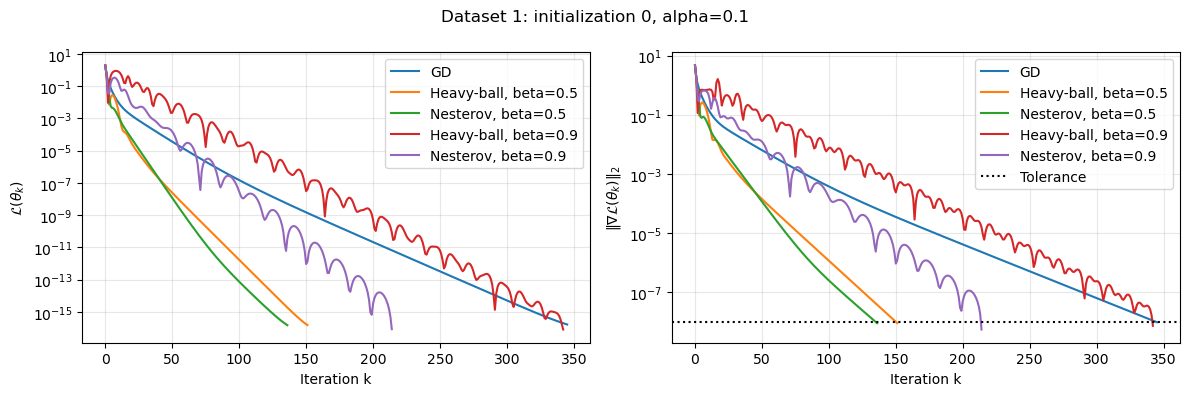

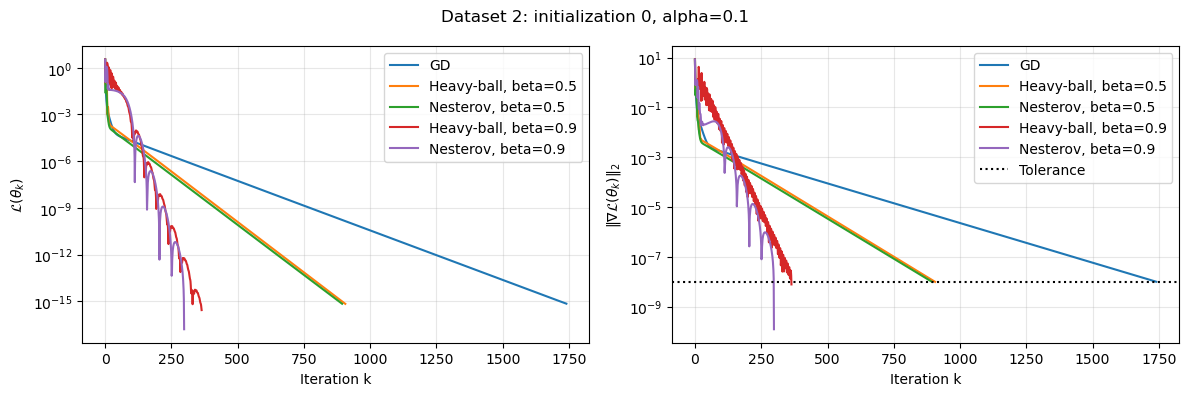

In [9]:

start_to_plot = 0
alpha_to_plot = 0.1

for number in range(1, len(models) + 1):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for result in results_week5:
        if (result['dataset'] != number or result['start'] != start_to_plot or result['alpha'] != alpha_to_plot or 'history' not in result):
            continue

        label = result['method']
        if result['beta'] is not None:
            label += f", beta={result['beta']}"

        history = result['history']

        axes[0].semilogy(history['obj'], label=label)
        axes[1].semilogy(history['grad'], label=label)

    axes[0].set_ylabel(r"$\mathcal{L}(\theta_k)$")
    axes[1].set_ylabel(r"$\|\nabla \mathcal{L}(\theta_k)\|_2$")
    axes[1].axhline(epsilon, color='black', linestyle=':', label='Tolerance')

    for ax in axes:
        ax.set_xlabel("Iteration k")
        ax.grid(True, alpha=0.3)
        ax.legend()

    fig.suptitle(f"Dataset {number}: "f"initialization {start_to_plot}, alpha={alpha_to_plot}")
    plt.tight_layout()
    plt.show()

### Numerical experiments for Newton

In [10]:
# Newton's method (week 6)

epsilon = 1e-8
max_iter = 10000
results_week6 = []

for number, model in enumerate(models, start=1):
    print(f"\nDATASET {number}")

    for start, theta_0 in enumerate(initial_values):
        print(f"\nInitial value {start}: {theta_0}")
        print(f"{'Method':<12} {'Updates':>8} {'Loss':>12} "f"{'||grad||':>12} {'Param. error':>12}")

        entry = {'dataset': number,'start': start,'method': 'Newton','alpha': None,'beta': None}

        try:
            with np.errstate(over='ignore', invalid='ignore', under='ignore'):
                theta, k, loss, history = model.newton(theta_0,epsilon=epsilon,max_iter=max_iter,track_history=True)

            grad_norm = float(LA.norm(model._gradient(theta)))
            parameter_error = float(LA.norm(theta - theta_true))

            entry.update({
                'status': 'gradient tolerance reached',
                'theta': theta,
                'updates': k,
                'loss': loss,
                'grad_norm': grad_norm,
                'parameter_error': parameter_error,
                'history': history})

            print(f"{'Newton':<12} {k:>8} {loss:>12.3e} "f"{grad_norm:>12.3e} {parameter_error:>12.3e}")

        except (RuntimeError, ValueError, LA.LinAlgError) as error:
            entry['status'] = str(error)
            print(f"{'Newton':<12} {error}")

        results_week6.append(entry)


DATASET 1

Initial value 0: [0. 0. 0.]
Method        Updates         Loss     ||grad|| Param. error
Newton              6    5.074e-17    2.139e-09    1.201e-08

Initial value 1: [1. 1. 1.]
Method        Updates         Loss     ||grad|| Param. error
Newton             10    4.736e-17    9.066e-15    1.028e-08

Initial value 2: [5. 5. 5.]
Method        Updates         Loss     ||grad|| Param. error
Newton             16    2.409e+00    3.888e-09    3.531e+01

Initial value 3: [-1. -1. -1.]
Method        Updates         Loss     ||grad|| Param. error
Newton              9    4.736e-17    3.181e-14    1.028e-08

Initial value 4: [10. 10. 10.]
Method        Updates         Loss     ||grad|| Param. error
Newton             11    2.409e+00    3.967e-09    3.528e+01

Initial value 5: [-0.73  1.47  0.37]
Method        Updates         Loss     ||grad|| Param. error
Newton              7    5.108e-17    2.954e-09    1.145e-08

DATASET 2

Initial value 0: [0. 0. 0.]
Method        Updates       

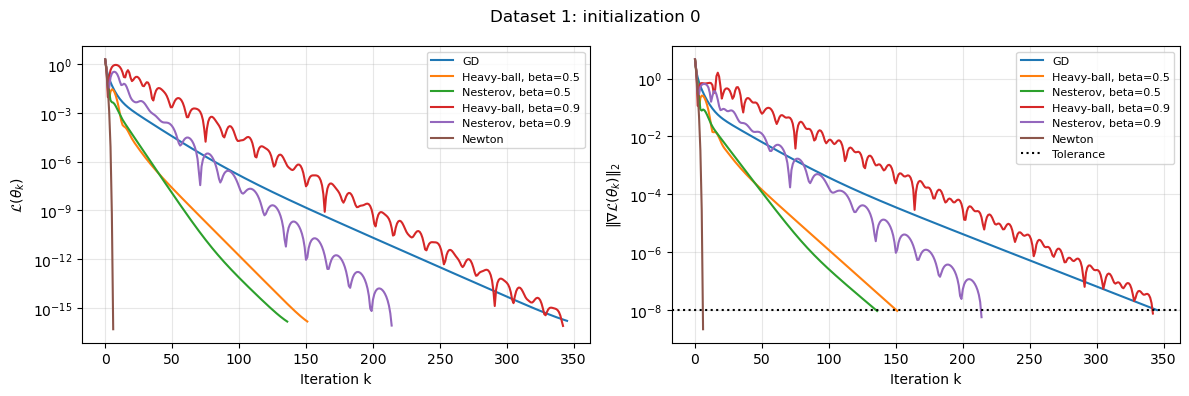

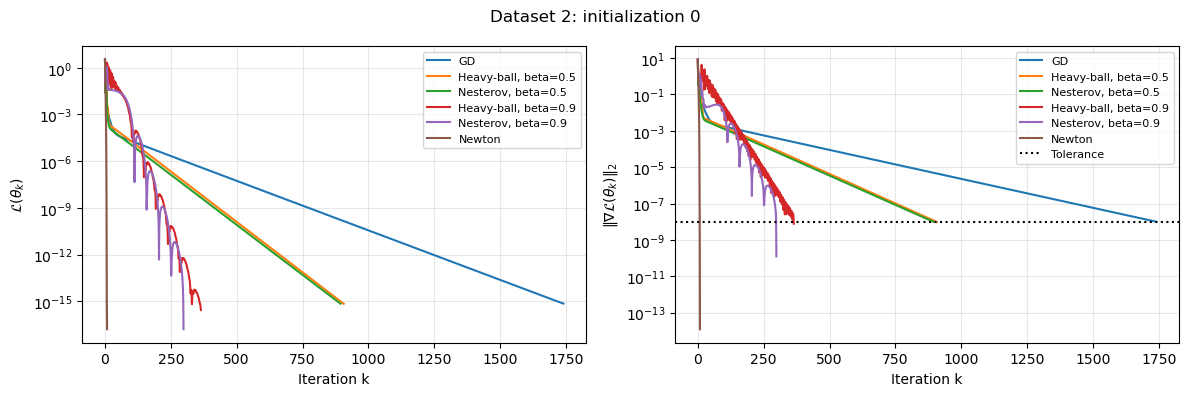

In [11]:
start_to_plot = 0
alpha_to_plot = 0.1

for number in range(1, len(models) + 1):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for result in results_week5 + results_week6:
        if (result['dataset'] != number or result['start'] != start_to_plot or 'history' not in result):
            continue

        is_newton = result['method'] == 'Newton'

        if not is_newton and result['alpha'] != alpha_to_plot:
            continue

        label = result['method']
        if result['beta'] is not None:
            label += f", beta={result['beta']}"

        history = result['history']

        axes[0].semilogy(history['obj'], label=label)
        axes[1].semilogy(history['grad'], label=label)

    axes[0].set_ylabel(r"$\mathcal{L}(\theta_k)$")
    axes[1].set_ylabel(r"$\|\nabla\mathcal{L}(\theta_k)\|_2$")
    axes[1].axhline(epsilon, color='black', linestyle=':', label='Tolerance')

    for ax in axes:
        ax.set_xlabel("Iteration k")
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right', fontsize=8)

    fig.suptitle(f"Dataset {number}: initialization {start_to_plot}")
    plt.tight_layout()
    plt.show()

### Experiments for the failure of Newton to decrease the objective

In [12]:
# Examining the first Newton step 

for number, model in enumerate(models, start=1):
    print(f"\nDATASET {number}")

    for start, theta_0 in enumerate(initial_values):
        print(f"\nInitial value {start}: {theta_0}")

        try:
            with np.errstate(over='ignore', invalid='ignore', under='ignore'):
                grad_k = model._gradient(theta_0)
                hessian = model._hessian(theta_0).copy()
                d_k = LA.solve(hessian, -grad_k)

                loss = model._objective(theta_0)
                loss_next = model._objective(theta_0 + d_k)

                smallest_eigenvalue = float(LA.eigvalsh(hessian)[0])
                directional_derivative = float(grad_k @ d_k)

            print(f"Smallest Hessian eigenvalue: "f"{smallest_eigenvalue:.3e}")
            print(f"grad^T d: {directional_derivative:.3e}")
            print(f"Initial loss: {loss:.6e}")
            print(f"Loss after full step: {loss_next:.6e}")
            print( "Descent direction:",directional_derivative < 0)
            print("Full step decreases loss:",loss_next < loss)

        except (ValueError, LA.LinAlgError) as error:
            print(error)


DATASET 1

Initial value 0: [0. 0. 0.]
Smallest Hessian eigenvalue: 3.853e+00
grad^T d: -2.522e+00
Initial loss: 1.859639e+00
Loss after full step: 3.295379e-01
Descent direction: True
Full step decreases loss: True

Initial value 1: [1. 1. 1.]
Smallest Hessian eigenvalue: -1.088e-01
grad^T d: -5.712e-01
Initial loss: 2.418672e-01
Loss after full step: 7.794053e+00
Descent direction: True
Full step decreases loss: False

Initial value 2: [5. 5. 5.]
Smallest Hessian eigenvalue: -2.207e-02
grad^T d: 6.065e-02
Initial loss: 2.348690e+00
Loss after full step: 2.386974e+00
Descent direction: False
Full step decreases loss: False

Initial value 3: [-1. -1. -1.]
Smallest Hessian eigenvalue: 4.064e+01
grad^T d: -4.476e+01
Initial loss: 4.038382e+01
Loss after full step: 1.234624e+01
Descent direction: True
Full step decreases loss: True

Initial value 4: [10. 10. 10.]
Smallest Hessian eigenvalue: -1.515e-04
grad^T d: 4.086e-04
Initial loss: 2.408535e+00
Loss after full step: 2.408793e+00
Desc